In [78]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [79]:
# load rthe dataset
df = pd.read_csv(r"C:\Users\ASFAK\Downloads\archive (1)\heart_disease_uci.csv")
# basic inspection
print('Shape:', df.shape)
print('\ncolumn names:\n', df.columns.tolist())
print('\nFirst 5 rows:', df.head)

Shape: (920, 16)

column names:
 ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

First 5 rows: <bound method NDFrame.head of       id  age     sex        dataset               cp  trestbps   chol    fbs  \
0      1   63    Male      Cleveland   typical angina     145.0  233.0   True   
1      2   67    Male      Cleveland     asymptomatic     160.0  286.0  False   
2      3   67    Male      Cleveland     asymptomatic     120.0  229.0  False   
3      4   37    Male      Cleveland      non-anginal     130.0  250.0  False   
4      5   41  Female      Cleveland  atypical angina     130.0  204.0  False   
..   ...  ...     ...            ...              ...       ...    ...    ...   
915  916   54  Female  VA Long Beach     asymptomatic     127.0  333.0   True   
916  917   62    Male  VA Long Beach   typical angina       NaN  139.0  False   
917  918   55    Male  VA Long Beach     asymptomatic    

In [80]:
# dropping non-clinical columns 
df = df.drop(columns=['id','dataset'])
print('shape after dropping id and dataset:', df.shape)
print('\nColumn names:', df.columns.tolist())

# check missing values if they exist
print('\nMissing values per column:')
print(df.isnull().sum())

# Check class's distribution (target column = 'num')
print("\nClass distribution (num):")
print(df['num'].value_counts().sort_index())

shape after dropping id and dataset: (920, 14)

Column names: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Missing values per column:
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64

Class distribution (num):
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


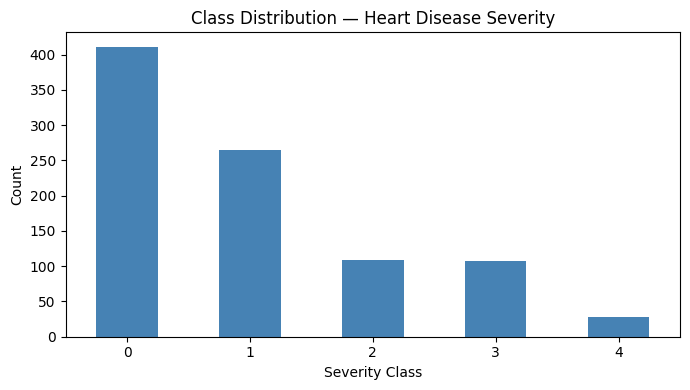

In [81]:
# Class distribution
plt.figure(figsize=(7, 4))
df['num'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Class Distribution — Heart Disease Severity')
plt.xlabel('Severity Class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150)
plt.show()



In [82]:
# now,lets handle missing values with sklearns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

#Separate numeric and categorical columns
numerical_columns = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
catagorial_columns = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

#now, impute missing values by appropriate values
# (A) Fill numeric values with median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

#(B) Verify no missing values remain
print("Missing values after imputation:")
print(df.isnull().sum())

#(C)Encode categorical columns 
le = LabelEncoder()
for col in catagorial_columns:
    df[col] = le.fit_transform(df[col].astype(str))

for col in catagorial_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nData types after encoding:")
print(df.dtypes)

#(D) Separate features and target 
X = df.drop(columns=['num'])
y = df['num']

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

#(E) Scale features 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFirst row of scaled features:")
print(X_scaled[0])

#(F) Train/test split 
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("\nClass distribution in training set:")
print(pd.Series(y_train).value_counts().sort_index())
print("\nClass distribution in test set:")
print(pd.Series(y_test).value_counts().sort_index())

Missing values after imputation:
age           0
sex           0
cp            0
trestbps      0
chol          0
fbs          90
restecg       2
thalch        0
exang        55
oldpeak       0
slope       309
ca          611
thal        486
num           0
dtype: int64

Data types after encoding:
age           int64
sex           int32
cp            int32
trestbps    float64
chol        float64
fbs           int32
restecg       int32
thalch      float64
exang         int32
oldpeak     float64
slope         int32
ca            int32
thal          int32
num           int64
dtype: object

Feature shape: (920, 13)
Target shape: (920,)

First row of scaled features:
[ 1.00738556  0.51693097  2.31986001  0.70517639  0.30364317  1.0074894
 -1.81355419  0.4897271  -0.79945036  1.36810909 -1.9289055  -1.73668542
 -1.81178491]

Training set size: (736, 13)
Test set size: (184, 13)

Class distribution in training set:
num
0    329
1    212
2     87
3     86
4     22
Name: count, dtype: int64

Cla

Class weights: {0: 0.4474164133738602, 1: 0.6943396226415094, 2: 1.6919540229885057, 3: 1.7116279069767442, 4: 6.6909090909090905}


Model: "MLP_HeartDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_29 (Dense)                │ (None, 15)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 25)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 25)             │           650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 25)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 20)             │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,885 (7.36 KB)

 Trainable params: 1,885 (7.36 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.2205 - loss: 1.7605 - val_accuracy: 0.2162 - val_loss: 1.6272
Epoch 2/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1903 - loss: 1.6277 - val_accuracy: 0.3919 - val_loss: 1.5641
Epoch 3/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1934 - loss: 1.5984 - val_accuracy: 0.4730 - val_loss: 1.5333
Epoch 4/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2613 - loss: 1.5764 - val_accuracy: 0.5000 - val_loss: 1.5014
Epoch 5/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2961 - loss: 1.5701 - val_accuracy: 0.4595 - val_loss: 1.4772
Epoch 6/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2976 - loss: 1.5763 - val_accuracy: 0.4865 - val_loss: 1.4632
Epoch 7/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3218 - loss: 1.5619 - val_accuracy: 0.4730 - val_loss: 1.4423
Epoch 8/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.3550 - loss: 1.5203 - val_accuracy: 0.4730 

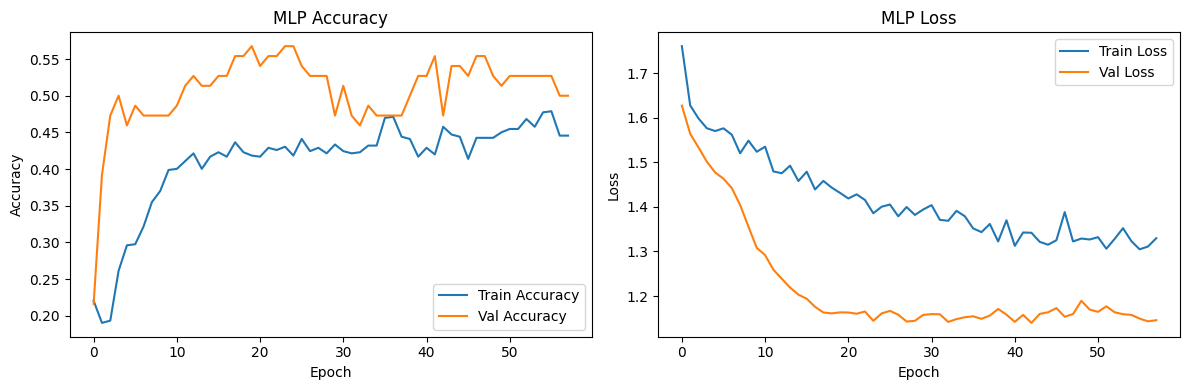

Plot saved as mlp_training_history.png


In [83]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report
from sklearn.utils.class_weight import compute_class_weight

#1.One-hot encode labels 
num_classes = 5
y_train_cat = to_categorical(y_train, num_classes)
y_test_cat  = to_categorical(y_test,  num_classes)

#2. Compute class weights to handle imbalance ─────────────────────────
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights_array))
print("Class weights:", class_weight_dict)

#3.Build MLP with Dropout 
mlp_model = keras.Sequential([
    layers.Input(shape=(13,)),
    layers.Dense(15, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(25, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(25, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(20, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
], name='MLP_HeartDisease')

mlp_model.summary()

# 4. Compile 
mlp_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

#5. Early stopping 
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)


# 6. Train 
history = mlp_model.fit(
    X_train, y_train_cat,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    class_weight=class_weight_dict,
    verbose=1
)

# 7. Evaluate 
loss, accuracy = mlp_model.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nMLP Test Accuracy: {accuracy * 100:.2f}%")
print(f"MLP Test Loss:     {loss:.4f}")

# 8. Classification report 
y_pred_mlp = np.argmax(mlp_model.predict(X_test), axis=1)
print("\nClassification Report (MLP):")
print(classification_report(y_test, y_pred_mlp,
      target_names=['Class 0','Class 1','Class 2','Class 3','Class 4'],
      zero_division=0))

# 9. Plot training history 
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('MLP Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('MLP Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('mlp_training_history.png', dpi=150)
plt.show()
print("Plot saved as mlp_training_history.png")

# Ensemble model (Random Forest classifier)

In [84]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns

# Build Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,      # 200 decision trees
    max_depth=10,          # max depth per tree
    min_samples_split=5,   # min samples to split a node
    min_samples_leaf=2,    # min samples at a leaf node
    class_weight='balanced', # handle class imbalance
    random_state=42
)

# Train
rf_model.fit(X_train, y_train)
print("Random Forest training complete.")



Random Forest training complete.


In [85]:
# evaluateion
# Predict
y_pred_rf = rf_model.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Test Accuracy: {rf_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf,
      target_names=['Class 0','Class 1','Class 2','Class 3','Class 4'],
      zero_division=0))

Random Forest Test Accuracy: 58.15%

Classification Report (Random Forest):
              precision    recall  f1-score   support

     Class 0       0.82      0.82      0.82        82
     Class 1       0.52      0.49      0.50        53
     Class 2       0.29      0.27      0.28        22
     Class 3       0.30      0.38      0.33        21
     Class 4       0.00      0.00      0.00         6

    accuracy                           0.58       184
   macro avg       0.38      0.39      0.39       184
weighted avg       0.58      0.58      0.58       184



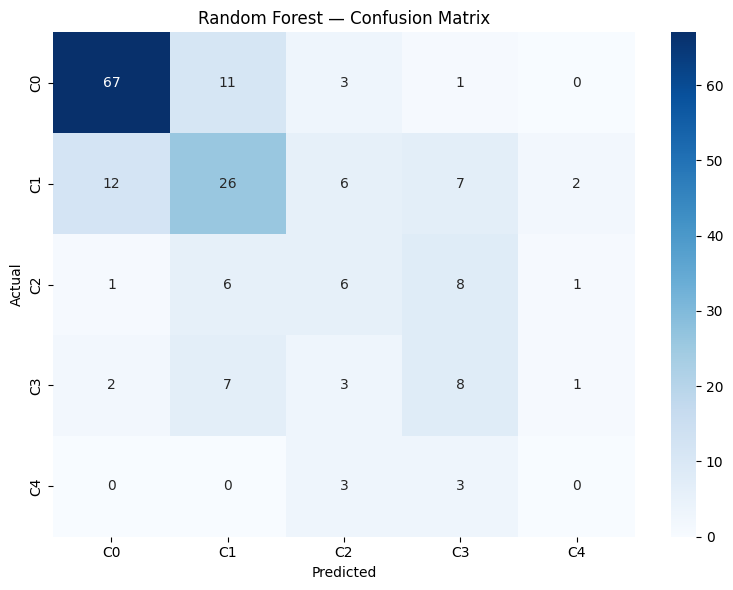

Confusion matrix saved.


In [86]:
# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['C0','C1','C2','C3','C4'],
            yticklabels=['C0','C1','C2','C3','C4'])
plt.title('Random Forest — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('rf_confusion_matrix.png', dpi=150)
plt.show()
print("Confusion matrix saved.")

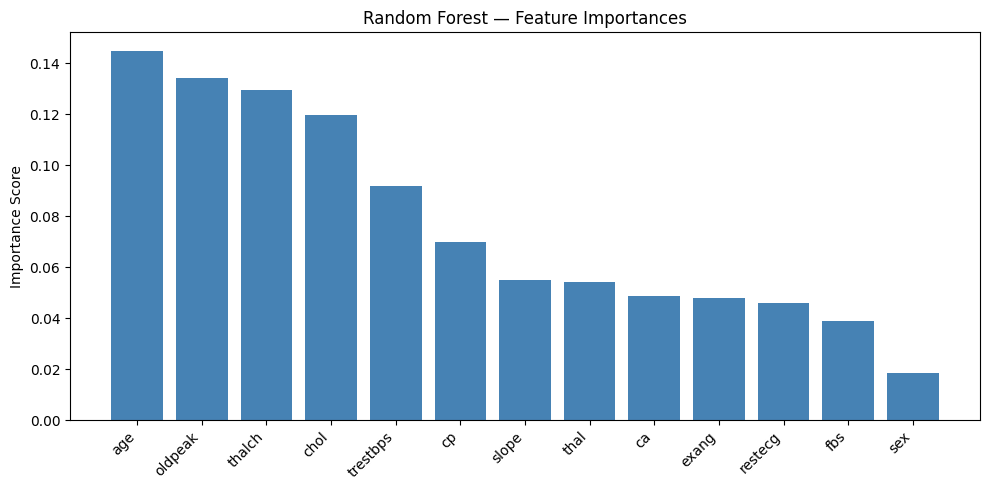

Feature importance plot saved.


In [87]:
# Feature importance
feature_names = ['age','sex','cp','trestbps','chol','fbs',
                 'restecg','thalch','exang','oldpeak','slope','ca','thal']

importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.bar(range(13), importances[indices], color='steelblue')
plt.xticks(range(13), [feature_names[i] for i in indices], rotation=45, ha='right')
plt.title('Random Forest — Feature Importances')
plt.ylabel('Importance Score')
plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150)
plt.show()
print("Feature importance plot saved.")

In [88]:
# MLP accuracy from Task A
mlp_accuracy = accuracy  # this variable was saved from Task A evaluation

print("=" * 40)
print("        MODEL COMPARISON (So Far)")
print("=" * 40)
print(f"  Task A — MLP         : {mlp_accuracy * 100:.2f}%")
print(f"  Task B — Random Forest: {rf_accuracy * 100:.2f}%")
print("=" * 40)

        MODEL COMPARISON (So Far)
  Task A — MLP         : 47.28%
  Task B — Random Forest: 58.15%


In [89]:
# CNN expects 3D input: (samples, timesteps, features)
# We reshape 13 features into shape (13, 1) — treating each feature as a timestep
X_train_cnn = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_cnn  = X_test.reshape(X_test.shape[0],  X_test.shape[1],  1)

print("X_train_cnn shape:", X_train_cnn.shape)
print("X_test_cnn shape: ", X_test_cnn.shape)

X_train_cnn shape: (736, 13, 1)
X_test_cnn shape:  (184, 13, 1)


In [90]:
#building model
import keras
from keras import layers

cnn_model = keras.Sequential([
    layers.Input(shape=(13, 1)),

    # Convolutional Block 1
    layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2, padding='same'),

    # Convolutional Block 2
    layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling1D(pool_size=2, padding='same'),

    # Convolutional Block 3
    layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),

    # Convolutional Block 4
    layers.Conv1D(filters=32, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),

    # Classification head
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(32, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
], name='CNN_HeartDisease')

cnn_model.summary()

Model: "CNN_HeartDisease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_12 (Conv1D)              │ (None, 13, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 13, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 7, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_13 (Conv1D)              │ (None, 7, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 7, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_14 (Conv1D)              │ (None, 4, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 4, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 4, 32)          │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 4, 32)          │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,133 (141.14 KB)

 Trainable params: 35,749 (139.64 KB)

 Non-trainable params: 384 (1.50 KB)

In [91]:
# Compile and Train
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_cnn = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

cnn_history = cnn_model.fit(
    X_train_cnn, y_train_cat,
    epochs=200,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop_cnn],
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.3097 - loss: 1.7570 - val_accuracy: 0.1757 - val_loss: 1.6180
Epoch 2/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.4079 - loss: 1.4433 - val_accuracy: 0.1351 - val_loss: 1.5946
Epoch 3/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4894 - loss: 1.2939 - val_accuracy: 0.2838 - val_loss: 1.5432
Epoch 4/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5514 - loss: 1.1905 - val_accuracy: 0.2432 - val_loss: 1.4980
Epoch 5/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5680 - loss: 1.1424 - val_accuracy: 0.2162 - val_loss: 1.4776
Epoch 6/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.6027 - loss: 0.9973 - val_accuracy: 0.2568 - val_loss: 1.4645
Epoch 7/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6073 - loss: 0.9482 - val_accuracy: 0.2838 - val_loss: 1.4253
Epoch 8/200
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6103 - loss: 0.9534 - val_accuracy: 0

In [92]:
# evaluation
cnn_loss, cnn_accuracy = cnn_model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"\nCNN Test Accuracy: {cnn_accuracy * 100:.2f}%")
print(f"CNN Test Loss:     {cnn_loss:.4f}")

y_pred_cnn = np.argmax(cnn_model.predict(X_test_cnn), axis=1)

print("\nClassification Report (CNN):")
print(classification_report(y_test, y_pred_cnn,
      target_names=['Class 0','Class 1','Class 2','Class 3','Class 4'],
      zero_division=0))


CNN Test Accuracy: 47.83%
CNN Test Loss:     1.2166
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step

Classification Report (CNN):
              precision    recall  f1-score   support

     Class 0       0.80      0.48      0.60        82
     Class 1       0.37      0.81      0.51        53
     Class 2       0.33      0.27      0.30        22
     Class 3       0.00      0.00      0.00        21
     Class 4       0.00      0.00      0.00         6

    accuracy                           0.48       184
   macro avg       0.30      0.31      0.28       184
weighted avg       0.50      0.48      0.45       184



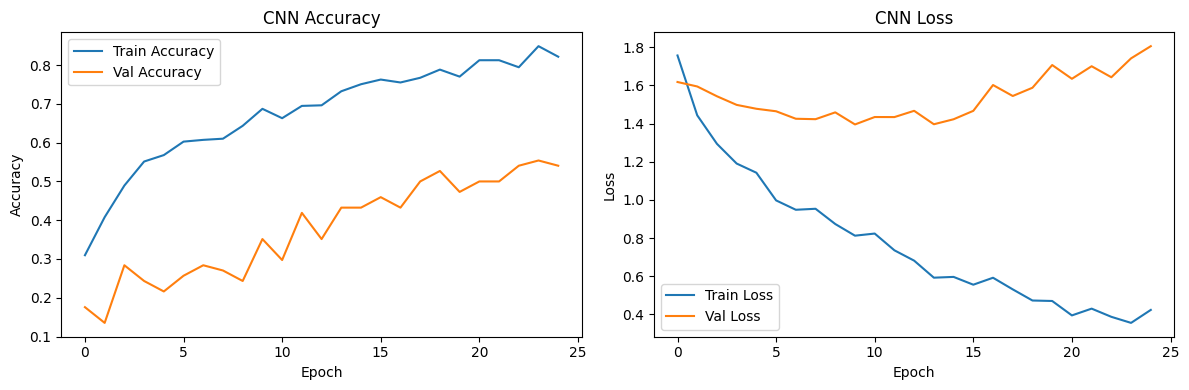

In [93]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['accuracy'], label='Train Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Val Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['loss'], label='Train Loss')
plt.plot(cnn_history.history['val_loss'], label='Val Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('cnn_training_history.png', dpi=150)
plt.show()

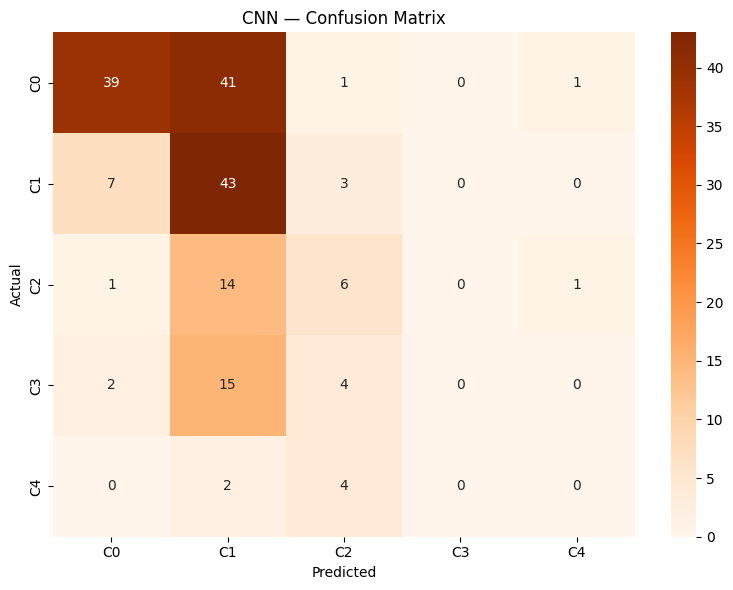

CNN confusion matrix saved.


In [94]:
# confusion matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['C0','C1','C2','C3','C4'],
            yticklabels=['C0','C1','C2','C3','C4'])
plt.title('CNN — Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('cnn_confusion_matrix.png', dpi=150)
plt.show()
print("CNN confusion matrix saved.")

In [95]:
# model comparison
print("=" * 45)
print("       FULL MODEL COMPARISON (Tasks A-C)")
print("=" * 45)
print(f"  Task A — MLP          : {mlp_accuracy * 100:.2f}%")
print(f"  Task B — Random Forest: {rf_accuracy * 100:.2f}%")
print(f"  Task C — CNN          : {cnn_accuracy * 100:.2f}%")
print("=" * 45)

       FULL MODEL COMPARISON (Tasks A-C)
  Task A — MLP          : 47.28%
  Task B — Random Forest: 58.15%
  Task C — CNN          : 47.83%


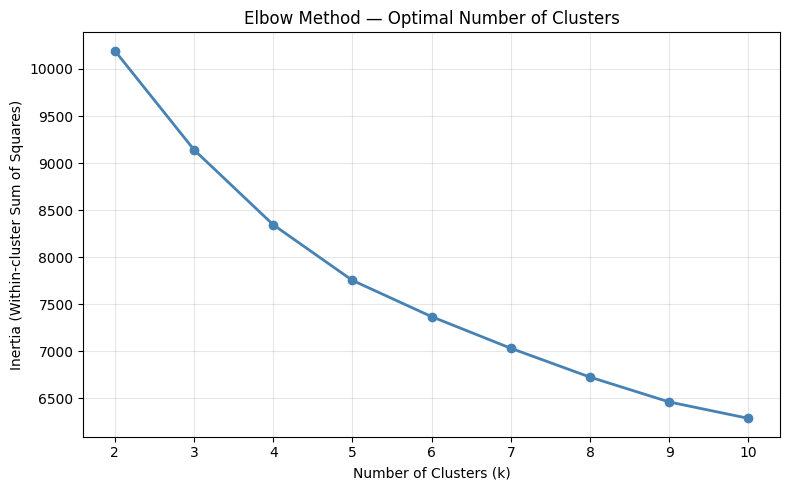

Elbow curve saved.


In [96]:
# Task D: Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Test k from 2 to 10
inertia = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia, marker='o', color='steelblue', linewidth=2)
plt.title('Elbow Method — Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster Sum of Squares)')
plt.xticks(k_range)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('elbow_curve.png', dpi=150)
plt.show()
print("Elbow curve saved.")

k=2 → Silhouette Score: 0.1433
k=3 → Silhouette Score: 0.1307
k=4 → Silhouette Score: 0.1412
k=5 → Silhouette Score: 0.1507
k=6 → Silhouette Score: 0.1578
k=7 → Silhouette Score: 0.1604
k=8 → Silhouette Score: 0.1522
k=9 → Silhouette Score: 0.1602
k=10 → Silhouette Score: 0.1527


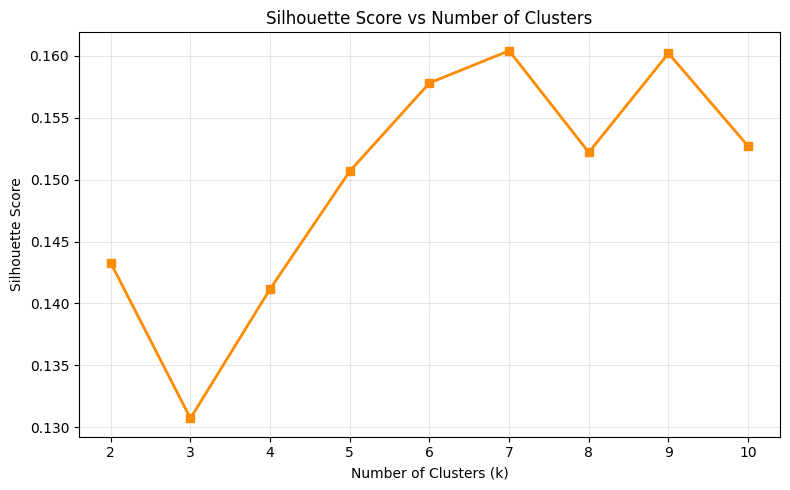

Silhouette plot saved.


In [97]:
# Silhouette score for each k
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k} → Silhouette Score: {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='s', color='darkorange', linewidth=2)
plt.title('Silhouette Score vs Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('silhouette_scores.png', dpi=150)
plt.show()
print("Silhouette plot saved.")

In [98]:
# fit final model with K= 5
# Use k=5 to match the 5 known severity classes
optimal_k = 5

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_scaled)

print(f"Final K-Means model fitted with k={optimal_k}")
print("\nCluster distribution:")
unique, counts = np.unique(cluster_labels, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Cluster {u}: {c} samples")

Final K-Means model fitted with k=5

Cluster distribution:
  Cluster 0: 236 samples
  Cluster 1: 147 samples
  Cluster 2: 155 samples
  Cluster 3: 153 samples
  Cluster 4: 229 samples


In [99]:
# Compare clusters against true severity labels
ari = adjusted_rand_score(y, cluster_labels)
nmi = normalized_mutual_info_score(y, cluster_labels)
sil = silhouette_score(X_scaled, cluster_labels)

print("=" * 45)
print("       CLUSTERING EVALUATION (k=5)")
print("=" * 45)
print(f"  Adjusted Rand Index (ARI) : {ari:.4f}")
print(f"  Normalised Mutual Info    : {nmi:.4f}")
print(f"  Silhouette Score          : {sil:.4f}")
print("=" * 45)
print("\nInterpretation:")
print(f"  ARI: ranges from -1 to 1 (1=perfect match, 0=random)")
print(f"  NMI: ranges from  0 to 1 (1=perfect match, 0=no info)")
print(f"  Silhouette: ranges -1 to 1 (higher=better separated)")

       CLUSTERING EVALUATION (k=5)
  Adjusted Rand Index (ARI) : 0.1330
  Normalised Mutual Info    : 0.1467
  Silhouette Score          : 0.1507

Interpretation:
  ARI: ranges from -1 to 1 (1=perfect match, 0=random)
  NMI: ranges from  0 to 1 (1=perfect match, 0=no info)
  Silhouette: ranges -1 to 1 (higher=better separated)


Cluster vs True Class distribution:
True Class    0   1   2   3   4
Cluster                        
0           185  43   5   3   0
1            42  40  24  30  11
2           121  23   6   4   1
3            17  60  41  31   4
4            46  99  33  39  12


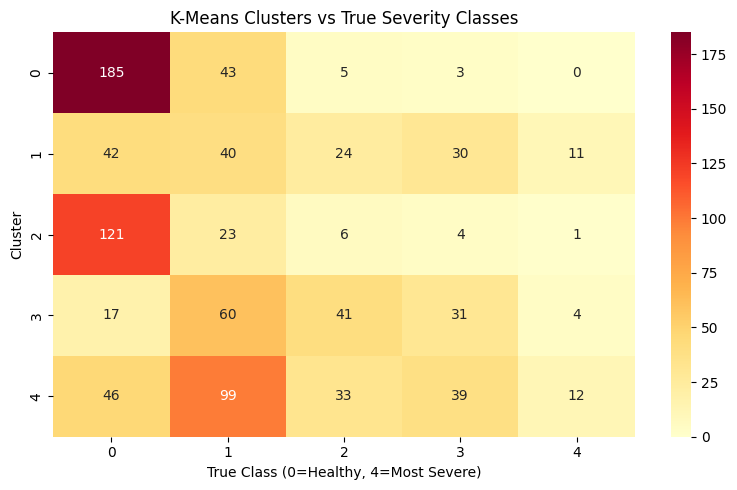

Cluster heatmap saved.


In [100]:
# cluster vs true label heatmap
import pandas as pd

# Cross-tabulation of clusters vs true labels
cross_tab = pd.crosstab(
    pd.Series(cluster_labels, name='Cluster'),
    pd.Series(y.values, name='True Class')
)

print("Cluster vs True Class distribution:")
print(cross_tab)

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd')
plt.title('K-Means Clusters vs True Severity Classes')
plt.xlabel('True Class (0=Healthy, 4=Most Severe)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.savefig('cluster_heatmap.png', dpi=150)
plt.show()
print("Cluster heatmap saved.")

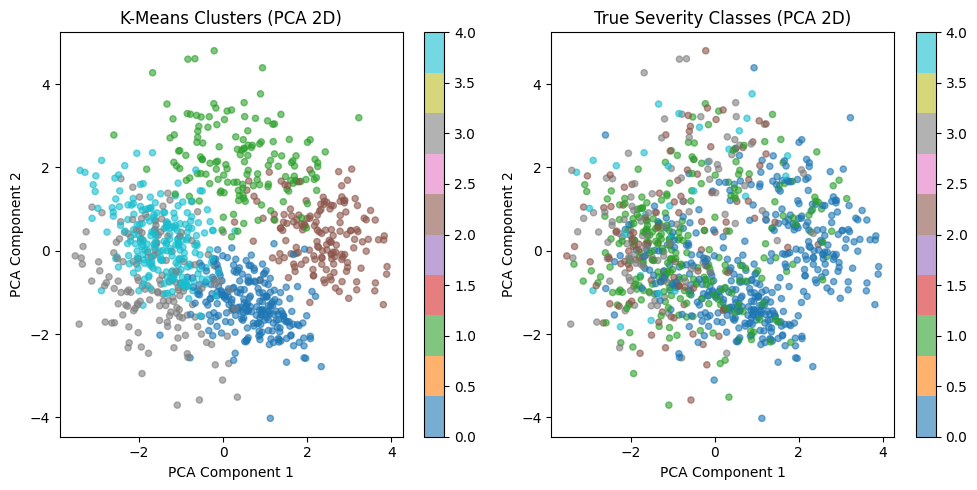

PCA cluster plot saved.


In [101]:
# PCA visualization of cluster
from sklearn.decomposition import PCA

# Reduce to 2D for visualisation
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 5))

# Plot by cluster
plt.subplot(1, 2, 1)
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                      c=cluster_labels, cmap='tab10', alpha=0.6, s=20)
plt.colorbar(scatter)
plt.title('K-Means Clusters (PCA 2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

# Plot by true labels
plt.subplot(1, 2, 2)
scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                       c=y.values, cmap='tab10', alpha=0.6, s=20)
plt.colorbar(scatter2)
plt.title('True Severity Classes (PCA 2D)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')

plt.tight_layout()
plt.savefig('pca_clusters.png', dpi=150)
plt.show()
print("PCA cluster plot saved.")